### Module 2 — The Predictive Modeling Framework
**ECON 381 · Oct 22**

### Outline

1. To explain, or to predict?
2. The framework for predictive modeling
   - 2.1 Data cleaning & exploratory analysis
   - 2.2 Partitioning — why cut the data?
   - 2.3 Preprocessing
   - 2.4 Replicate on test — and the many faces of **leakage**
   - 2.5 Cross-validation
3. Summary

---
### 1 · To explain, or to predict?

| | Econometrics (explain) | Machine learning (predict) |
|---|---|---|
| *Focus* | the coefficient **β̂** | the prediction **ŷ** |
| *Main Question* | is this estimate *credible*? | is this accurate *on new data*? |
| *A variable earns its place by* | causal interpretation | predictive contribution |
| *Success is judged by* | identification, theory | out-of-sample performance |

<br>

- Same toolbox, different goals — most real-world confusion comes from mixing the two
- A model can predict superbly with meaningless coefficients — and vice versa
- Vocabulary shift: dependent variable → **label** · independent variables → **features** · estimation → **training**
- Modules 1–5 focus on predictive modeling · Module 6 Machine Learning for Econometrics

---
### 2 · The Framwork for Predictive Modeling

Every predictive modeling project — in this course and in industry — follows the same spine:
![The Predictive Modeling Pipeline](https://raw.githubusercontent.com/sparks5969/advanced_data_analysis/main/pipeline_figure.png)



---
### 2.1 · Data cleaning & exploratory analysis

— **Project 1 is this stage**: impossible dates, structured missingness, suspicious ranges, etc.
- **Cleaning** here means **rule-based** fixes: an impossible date is wrong *no matter how the data will later be split*
- Exploratory analysis: schema, ranges, missingness structure — you cannot model what you haven't looked at
- No statistic or parameter is **learned** from the data in this stage
- Output: a dataset you can describe (your executive summary!) + Ready for next step analysis

---
### 2.2 · Data Partitioning

**A predictive model must learn the *pattern*, not the *noise*.**

- Any data has both systematic pattern and idiosyncratic noise
- A flexible enough model can fit *everything* — including the noise, which will never repeat
- Performance on data the model has seen is therefore not evidence of quality
- The cure: hold out a **test set** the model never touches — the only honest mirror

🖱️ **Live demo:** [madrury.github.io/smoothers](https://madrury.github.io/smoothers/) — what do you wanted to "learn" from the data.

Let's also see it in one picture of our own:

### Demo with a real dataset: the Auto MPG classic

**398 US car models, 1970–1982** — the dataset of the oil-crisis decade (two oil shocks, the first fuel-economy standards, the rise of Japanese imports).


| Column | Meaning |
|---|---|
| `mpg` | fuel efficiency, miles per gallon — **the label y we predict** |
| `horsepower` | engine power (6 cars missing it → a stage-1 cleaning moment) |
| `cylinders` | number of cylinders (3–8) |
| `displacement` | engine size, cubic inches |
| `weight` | vehicle weight, lbs |
| `acceleration` | seconds from 0 to 60 mph |
| `model_year` | 1970–1982 |
| `origin` | usa / europe / japan |
| `name` | model name ("chevrolet chevelle malibu", "toyota corolla", …) |

### Let's start with a simple polynomial regression

One feature to begin with — predict fuel efficiency from **engine power alone**, with a polynomial of **degree k** — and the degree is our flexibility dial:

- **Degree 1** (a straight line — the simple regression you know):
$$\text{mpg} = \beta_0 + \beta_1 \cdot \text{hp} + \varepsilon$$
- **Degree 2** (a quadratic — the curve can bend once):
$$\text{mpg} = \beta_0 + \beta_1 \cdot \text{hp} + \beta_2 \cdot \text{hp}^2 + \varepsilon$$
- **Degree k** (the curve can bend k−1 times):
$$\text{mpg} = \beta_0 + \beta_1 \cdot \text{hp} + \beta_2 \cdot \text{hp}^2 + \cdots + \beta_k \cdot \text{hp}^k + \varepsilon$$

Two things to notice:

1. **Every one of these is still OLS.** The model is *linear in the coefficients* — we just added hp², hp³, … as extra regressors. The degree-15 monster you are about to see is estimated by the same least squares you learned in econometrics.
2. **Each extra degree buys flexibility** — the freedom to bend — and flexibility is exactly what we are about to learn to fear.

In [1]:
# setup and load the data
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score, KFold
plt.rcParams["figure.dpi"] = 110
#
# load + the pipeline in action: clean (rule-based), then PARTITION
from sklearn.model_selection import train_test_split

cars = pd.read_csv("https://raw.githubusercontent.com/sparks5969/course-advanced-data-analysis/main/mpg.csv").dropna(subset=["horsepower"])   # stage 1: cleaning
train, test = train_test_split(cars, test_size=0.3, random_state=7)   # stage 2: partition
x_tr, y_tr = train["horsepower"].values, train["mpg"].values
x_te, y_te = test["horsepower"].values,  test["mpg"].values
print(len(train), "training cars,", len(test), "test cars")

274 training cars, 118 test cars


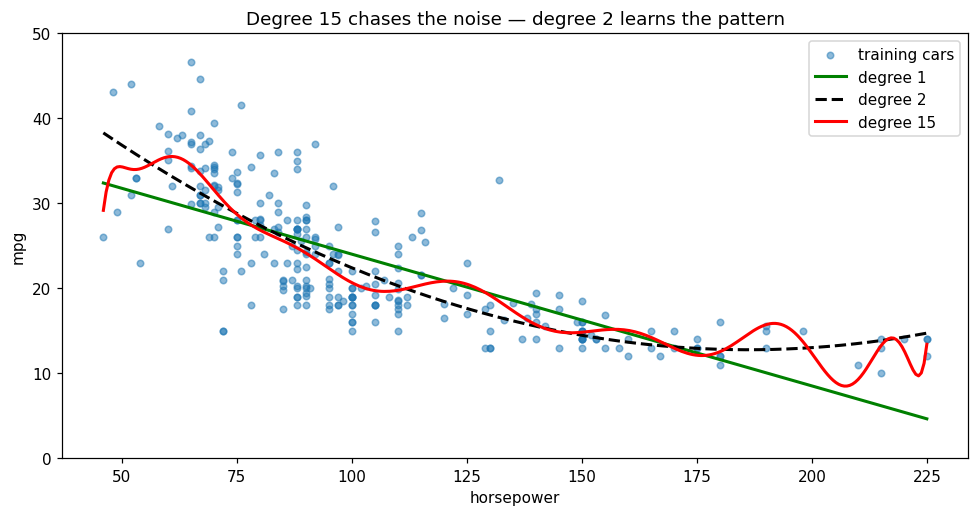

In [2]:
# fit three polynomials ON TRAIN ONLY and look at them
def polyfit_scaled(x, y, deg):        # rescale x for numerical stability
    return np.polyfit(x/100, y, deg)
def polyval_scaled(coef, x):
    return np.polyval(coef, x/100)

grid = np.linspace(x_tr.min(), x_tr.max(), 300)
plt.figure(figsize=(9,4.8))
plt.scatter(x_tr, y_tr, s=18, alpha=0.5, label="training cars")
for deg, style in [(1,"g-"), (2,"k--"), (15,"r-")]:
    c = polyfit_scaled(x_tr, y_tr, deg)
    plt.plot(grid, polyval_scaled(c, grid), style, lw=2, label=f"degree {deg}")
plt.ylim(0, 50); plt.xlabel("horsepower"); plt.ylabel("mpg")
plt.title("Degree 15 chases the noise — degree 2 learns the pattern")
plt.legend(); plt.tight_layout(); plt.show()

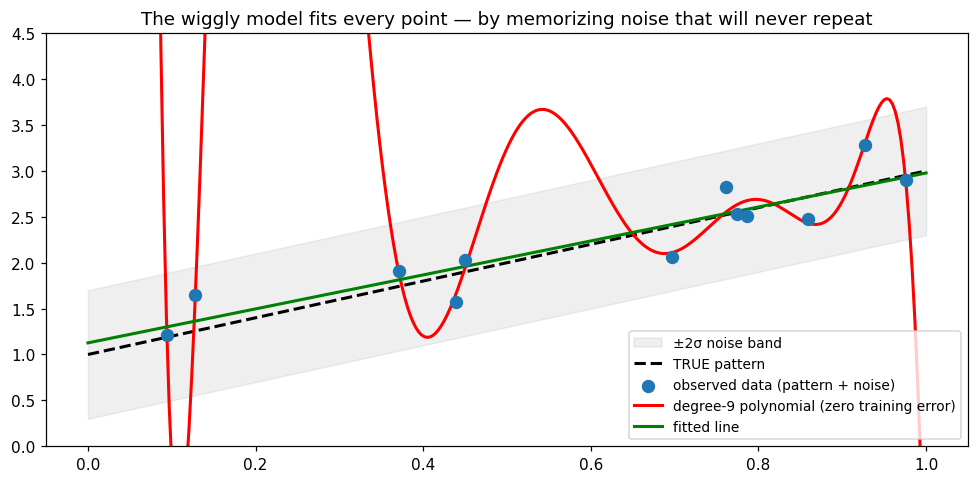

In [ ]:
# Learning the pattern vs. memorizing the noise (synthetic dataset)
rng = np.random.default_rng(42)
x = np.sort(rng.uniform(0, 1, 12)); y_true = 1 + 2*x
y = y_true + rng.normal(0, 0.35, size=x.size)
grid = np.linspace(0, 1, 300)

plt.figure(figsize=(9,4.5))
plt.fill_between(grid, 1+2*grid-0.7, 1+2*grid+0.7, alpha=0.12, color="gray", label="±2σ noise band")
plt.plot(grid, 1+2*grid, "k--", lw=2, label="TRUE pattern")
plt.scatter(x, y, zorder=5, s=60, label="observed data (pattern + noise)")
coef = np.polyfit(x, y, deg=9)
plt.plot(grid, np.polyval(coef, grid), "r-", lw=2, label="degree-9 polynomial (zero training error)")
plt.plot(grid, np.polyval(np.polyfit(x, y, 1), grid), "g-", lw=2, label="fitted line")
plt.ylim(0, 4.5); plt.legend(fontsize=9); plt.title("The wiggly model fits every point — by memorizing noise that will never repeat")
plt.tight_layout(); plt.show()
# Even the TRUE model can't beat the noise floor (σ²) — chasing zero training error means chasing noise.

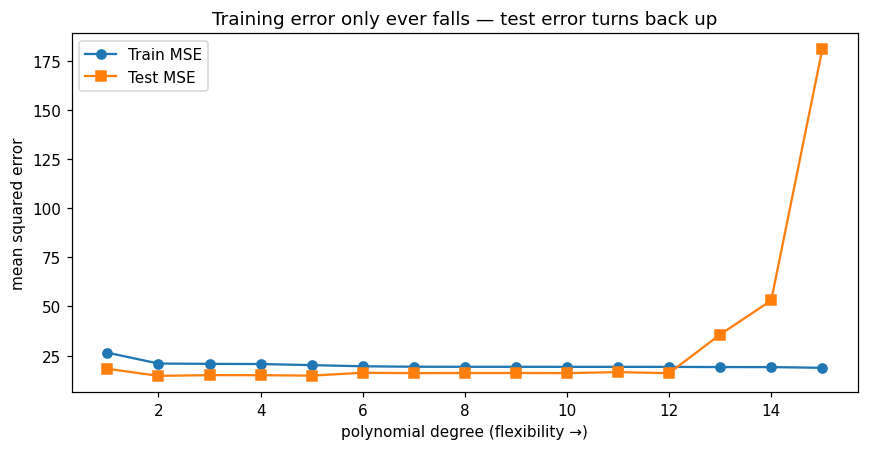

degree with best TRAIN error: 15  (always the most flexible)
degree with best TEST  error: 2


In [3]:
# the classic picture: train vs test error as flexibility grows
from sklearn.metrics import mean_squared_error
degrees = range(1, 16); tr_err, te_err = [], []
for d in degrees:
    c = polyfit_scaled(x_tr, y_tr, d)
    tr_err.append(mean_squared_error(y_tr, polyval_scaled(c, x_tr)))
    te_err.append(mean_squared_error(y_te, polyval_scaled(c, x_te)))
plt.figure(figsize=(8,4.2))
plt.plot(degrees, tr_err, "o-", label="Train MSE")
plt.plot(degrees, te_err, "s-", label="Test MSE")
plt.xlabel("polynomial degree (flexibility →)"); plt.ylabel("mean squared error")
plt.title("Training error only ever falls — test error turns back up")
plt.legend(); plt.tight_layout(); plt.show()
print("degree with best TRAIN error:", degrees[int(np.argmin(tr_err))], " (always the most flexible)")
print("degree with best TEST  error:", degrees[int(np.argmin(te_err))])

### Another way to train the model: a decision tree

A **decision tree** predicts differently: it cuts the horsepower range into intervals (*"hp ≤ 93? hp ≤ 127?"*) and predicts the **average mpg of the training cars in each interval** — a step function instead of a curve.

- Its flexibility dial is **depth**: how many times it may split. Depth 1 = two steps; each extra level can double the number of steps
- Different machinery, same question: does more flexibility help, or does it start memorizing?

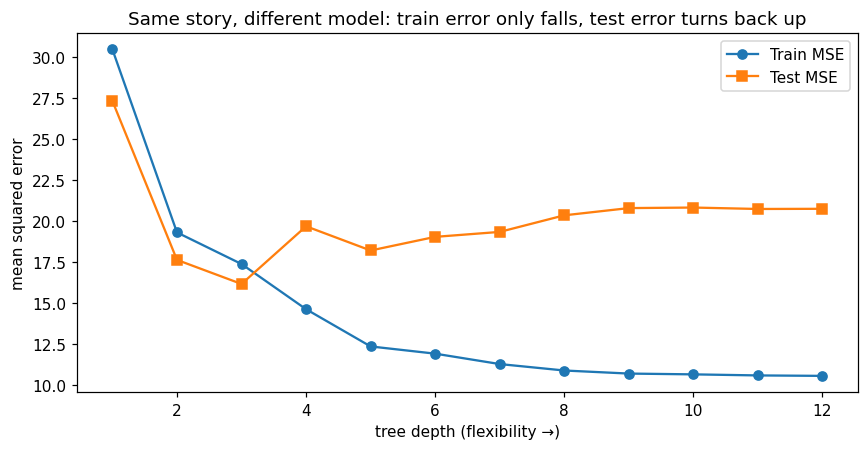

In [ ]:
# the same experiment, tree edition: train vs test error as depth grows
from sklearn.tree import DecisionTreeRegressor

X_tr_, X_te_ = x_tr.reshape(-1,1), x_te.reshape(-1,1)
depths = range(1, 13); tr_err, te_err = [], []
for d in depths:
    t = DecisionTreeRegressor(max_depth=d, random_state=0).fit(X_tr_, y_tr)
    tr_err.append(mean_squared_error(y_tr, t.predict(X_tr_)))
    te_err.append(mean_squared_error(y_te, t.predict(X_te_)))
plt.figure(figsize=(8,4.2))
plt.plot(depths, tr_err, "o-", label="Train MSE")
plt.plot(depths, te_err, "s-", label="Test MSE")
plt.xlabel("tree depth (flexibility →)"); plt.ylabel("mean squared error")
plt.title("Same story, different model: train error only falls, test error turns back up")
plt.legend(); plt.tight_layout(); plt.show()

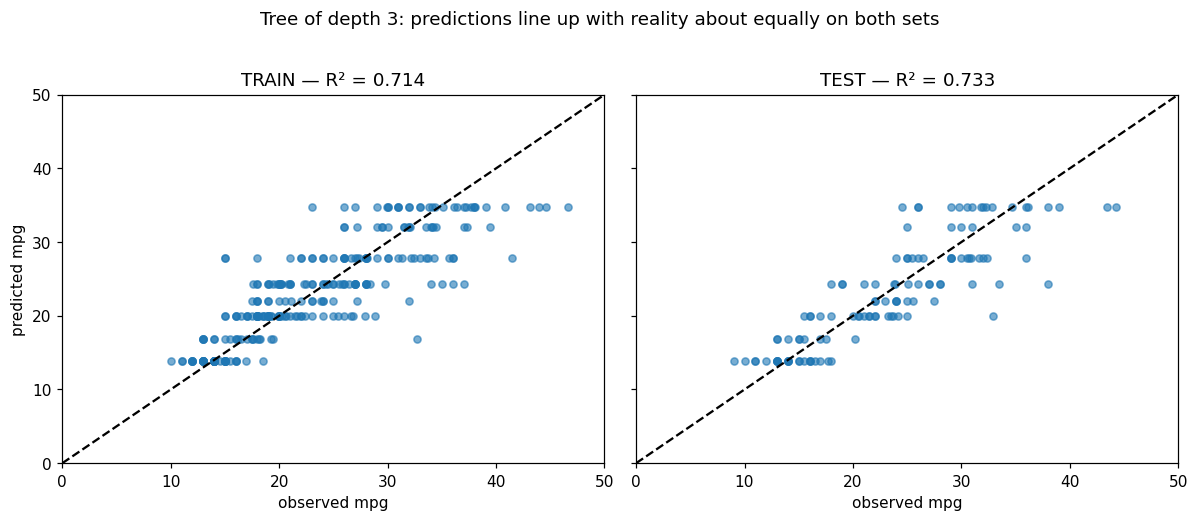

In [ ]:
# observed vs. predicted, train (left) and test (right) — a REASONABLE tree (depth 3)
from sklearn.metrics import r2_score

def tree_panels(depth):
    t = DecisionTreeRegressor(max_depth=depth, random_state=0).fit(X_tr_, y_tr)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
    for ax, (X, y, name) in zip(axes, [(X_tr_, y_tr, "TRAIN"), (X_te_, y_te, "TEST")]):
        pred = t.predict(X)
        ax.scatter(y, pred, s=22, alpha=0.6)
        ax.plot([0,50],[0,50],"k--",lw=1.5)      # the 45° line: perfect prediction
        ax.set_xlim(0,50); ax.set_ylim(0,50)
        ax.set_xlabel("observed mpg"); ax.set_title(f"{name} — R² = {r2_score(y, pred):.3f}")
    axes[0].set_ylabel("predicted mpg")
    fig.suptitle(f"Tree of depth {depth}: predictions line up with reality about equally on both sets", y=1.02)
    plt.tight_layout(); plt.show()

tree_panels(3)
# Both panels hug the 45° line about equally — the model GENERALIZES.
# (The horizontal bands are the tree's steps: every car in an interval gets
#  the same predicted mpg — the average of its training neighbors.)

### A extreme case: a *perfect* fit

A deep **decision tree** can split the data again and again until every training car sits in its own leaf — a perfect memorizer. Two facts to hold together:

- A deep tree on the **real features** memorizes train (R² = 1.000) and still scores ≈ 0.76 on test — because the data *has* signal.
- Now strip the signal away entirely. We hand the same tree **five columns of pure random numbers** and ask it to "predict" mpg:

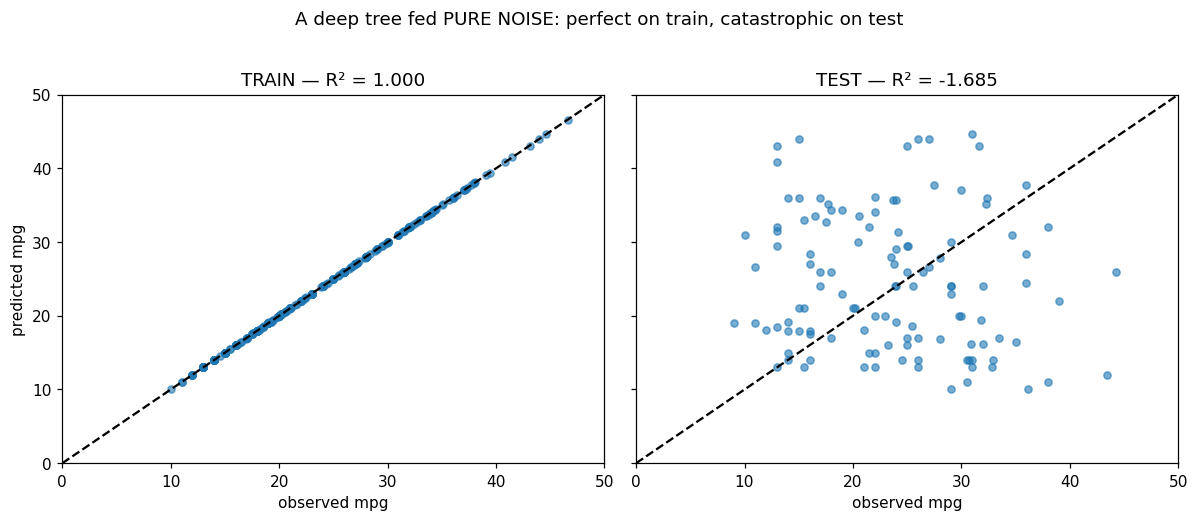

In [ ]:
# a deep tree trained on PURE NOISE
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score

rng = np.random.default_rng(42)
Z_tr = rng.normal(size=(len(x_tr), 5))     # five columns of random numbers
Z_te = rng.normal(size=(len(x_te), 5))

memorizer = DecisionTreeRegressor(random_state=0).fit(Z_tr, y_tr)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
for ax, (Z, y, name) in zip(axes, [(Z_tr, y_tr, "TRAIN"), (Z_te, y_te, "TEST")]):
    pred = memorizer.predict(Z)
    ax.scatter(y, pred, s=22, alpha=0.6)
    ax.plot([0,50],[0,50],"k--",lw=1.5)
    ax.set_xlim(0,50); ax.set_ylim(0,50)
    ax.set_xlabel("observed mpg"); ax.set_title(f"{name} — R² = {r2_score(y, pred):.3f}")
axes[0].set_ylabel("predicted mpg")
fig.suptitle("A deep tree fed PURE NOISE: perfect on train, catastrophic on test", y=1.02)
plt.tight_layout(); plt.show()

**Read the two panels:**

- TRAIN: every point *exactly on* the 45° line. R² = 1.000. Flawless.
- TEST: a shotgun blast. R² ≈ **−1.7** — *worse than predicting the class average for everyone.*

The model never saw any signal — there was none to see. It simply **memorized** which random numbers went with which mpg. Memorization looks identical to learning *on the training set*; only held-out data can tell them apart.

> **A perfect training fit proves nothing.**

---
### 2.3 · Preprocessing — getting data model-ready

After the split, the training set gets prepared for modeling. The steps differ project to project, but the usual suspects:

| Step | Example | What is *learned* from data |
|---|---|---|
| **Missing-value imputation** | fill missing income with the median; kNN imputation | the median / the neighbors |
| **Scaling / standardization** | subtract mean, divide by SD | the mean and SD |
| **Categorical encoding** | one-hot a city column; ordinal-encode quality ratings | the category list |
| **Skew transforms** | log of prices or incomes | (rule-like, but thresholds may be learned) |
| **Outlier handling** | cap at the 99th percentile | the percentile |
| **Feature engineering** | ratios, interactions, date parts | sometimes nothing, sometimes a lot |

- The pattern to notice: **almost every step learns a number from the data**
- Therefore every one of them is **fit on the training set only** — the test set must not contribute a single digit
- The fitted steps together form the **blueprint** — a recipe written on train, to be replayed verbatim

---
### 2.4 · Replicate on test — and the many faces of LEAKAGE

**The rule:** the test set receives the train-fitted blueprint, applied unchanged. Never re-fit anything on test.

**Leakage** = information from outside the training set sneaking into training. It always *inflates* measured performance — you find out only when the model faces genuinely new data. The classic faces:

1. **Scale-before-split** — standardize all rows, then split: the scaler's mean already "knows" the test rows
2. **Impute-with-everything** — fill missing values using the full data's median: test values leaked into train
3. **Target leakage** — a feature that secretly encodes the answer: predicting loan default using *"late fees charged"*; predicting fraud using *"chargeback filed"*
4. **Temporal leakage** — training on information from *after* the moment of prediction: forecasting Tuesday's price with a feature computed from Wednesday
5. **Tuning on test** — trying many models and reporting the test score of the winner (we'll commit this sin live, below)

- The common thread: the measured score stops being a forecast of real-world performance

---
### 2.5 · Cross-validation — tuning without spending the test set

We need to choose things: tree depth, penalty strength, which model. Choosing takes data. But:

Cross-validation — make the training set play both roles, in turns.**

k-fold CV: split *train* into k folds · each fold takes one turn as the judge while the other k−1 train · average the k scores. Let's commit the sin first, then do it right — **choosing the polynomial degree** for our cars:

In [ ]:
# one cross-validation, by hand — the mechanics (degree 2 as our example)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression

def poly_model(deg):
    return make_pipeline(StandardScaler(), PolynomialFeatures(deg), LinearRegression())

X_tr, X_te = x_tr.reshape(-1,1), x_te.reshape(-1,1)

kf = KFold(n_splits=5, shuffle=True, random_state=0)
scores = []
for k, (i_tr, i_va) in enumerate(kf.split(X_tr)):
    m = poly_model(2).fit(X_tr[i_tr], y_tr[i_tr])      # train on 4 folds
    r2 = m.score(X_tr[i_va], y_tr[i_va])               # judge on the held-out fold
    scores.append(r2)
    print(f"fold {k}: train on {len(i_tr)} cars, validate on {len(i_va)} → R² = {r2:.3f}")
print(f"\nthe CV score of degree 2 = the average: {np.mean(scores):.3f}")
# five trainings, five judgments, one average — no test data involved

fold 0: train on 219 cars, validate on 55 → R² = 0.694
fold 1: train on 219 cars, validate on 55 → R² = 0.686
fold 2: train on 219 cars, validate on 55 → R² = 0.486
fold 3: train on 219 cars, validate on 55 → R² = 0.647
fold 4: train on 220 cars, validate on 54 → R² = 0.701

the CV score of degree 2 = the average: 0.643


That is **one** cross-validation — the full procedure for a single candidate model. `cross_val_score` does exactly this loop in one line. Now the real use: run it for **all fifteen degrees** and let the averages compete:

In [ ]:
# the wrong way first: pick the degree by peeking at test
peek = max(range(1,16), key=lambda d: poly_model(d).fit(X_tr, y_tr).score(X_te, y_te))
print("degree picked by peeking at test:", peek, " ← the test set is now spent")

# done right: 5-fold CV inside train only, for every degree
cv_scores = {d: cross_val_score(poly_model(d), X_tr, y_tr, cv=5) for d in range(1,16)}
means = {d: s.mean() for d, s in cv_scores.items()}
best_raw = max(means, key=means.get)
print("\nbest raw CV score: degree", best_raw, f"(CV R² = {means[best_raw]:.3f})")
print("but look how flat the curve is:", {d: round(float(means[d]),3) for d in [1,2,3,5,7,10]})

# the ONE-STANDARD-ERROR RULE: among degrees within 1 SE of the best, take the SIMPLEST
se_best = cv_scores[best_raw].std() / np.sqrt(5)
best = min(d for d in means if means[d] >= means[best_raw] - se_best)
print("simplest degree within 1 SE of the best:", best, " ← parsimony wins ties")

final = poly_model(best).fit(X_tr, y_tr)
print("final, honest test R²:", round(final.score(X_te, y_te), 3), " ← test set touched exactly once")

degree picked by peeking at test: 2  ← the test set is now spent

best raw CV score: degree 7 (CV R² = 0.669)
but look how flat the curve is: {1: 0.556, 2: 0.654, 3: 0.653, 5: 0.659, 7: 0.669, 10: 0.662}
simplest degree within 1 SE of the best: 2  ← parsimony wins ties
final, honest test R²: 0.759  ← test set touched exactly once


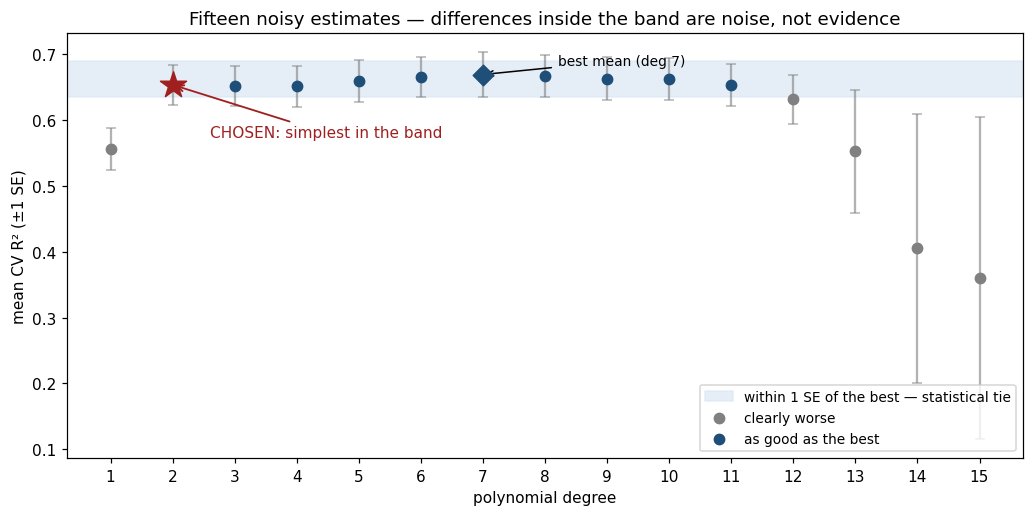

In [ ]:
# the one-SE rule, visualized: 15 noisy means, one band, one winner
degs   = sorted(cv_scores)
m      = np.array([cv_scores[d].mean() for d in degs])
se     = np.array([cv_scores[d].std()/np.sqrt(5) for d in degs])
lo     = means[best_raw] - se_best          # bottom of the champion's band

plt.figure(figsize=(9.5, 4.8))
plt.axhspan(lo, m.max()+0.02, color="#dbe7f5", alpha=0.7, zorder=0,
            label="within 1 SE of the best — statistical tie")
in_band = m >= lo
plt.errorbar(degs, m, yerr=se, fmt="none", ecolor="gray", alpha=0.6, capsize=3, zorder=2)
plt.scatter(np.array(degs)[~in_band], m[~in_band], color="gray", s=45, zorder=3, label="clearly worse")
plt.scatter(np.array(degs)[in_band],  m[in_band],  color="#1f4e79", s=45, zorder=3, label="as good as the best")
plt.scatter([best_raw], [means[best_raw]], marker="D", s=90, color="#1f4e79", zorder=4)
plt.annotate("best mean (deg 7)", (best_raw, means[best_raw]), xytext=(best_raw+1.2, means[best_raw]+0.015),
             fontsize=9, arrowprops=dict(arrowstyle="->", lw=1))
plt.scatter([best], [means[best]], marker="*", s=320, color="#a02020", zorder=5)
plt.annotate("CHOSEN: simplest in the band", (best, means[best]), xytext=(best+0.6, means[best]-0.08),
             fontsize=10, color="#a02020", arrowprops=dict(arrowstyle="->", color="#a02020", lw=1.2))
plt.xlabel("polynomial degree"); plt.ylabel("mean CV R² (±1 SE)")
plt.title("Fifteen noisy estimates — differences inside the band are noise, not evidence")
plt.legend(loc="lower right", fontsize=9)
plt.xticks(degs); plt.tight_layout(); plt.show()

**"But the peek picked 2 as well — so why bother?"** By luck of *this particular split*. A method you can only trust when it happens to agree with the honest one is not a method. Watch what happens when we re-deal the train/test cards 20 times:

               peeking at test  CV + one-SE rule
degree chosen                                   
2                            3                19
3                            2                 0
5                            1                 1
6                            4                 0
7                            3                 0
8                            1                 0
10                           1                 0
11                           1                 0
15                           4                 0


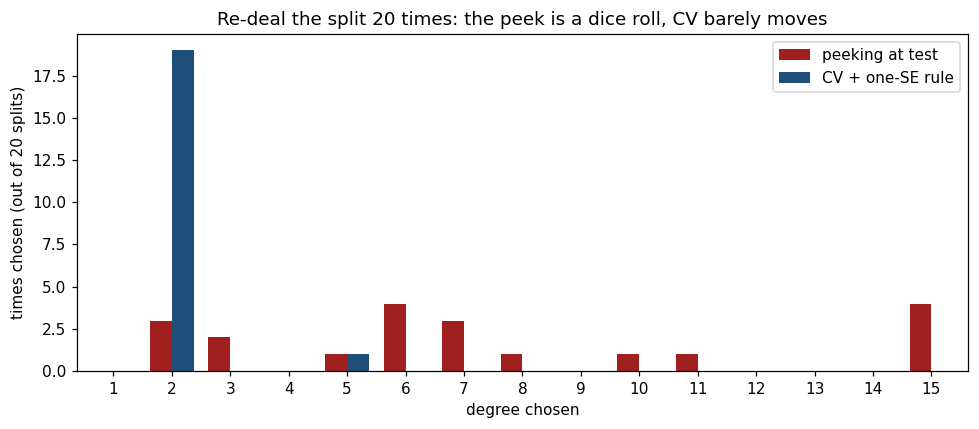

In [ ]:
# re-deal the split 20 times: how stable is each "method"?
from collections import Counter
peeks, cv_picks = [], []
for seed in range(20):
    tr_i, te_i = train_test_split(np.arange(len(x_tr)+len(x_te)), test_size=0.3, random_state=seed)
    hp  = np.concatenate([x_tr, x_te]); mpg = np.concatenate([y_tr, y_te])
    Xa, ya = hp[tr_i].reshape(-1,1), mpg[tr_i]
    Xb, yb = hp[te_i].reshape(-1,1), mpg[te_i]
    peeks.append(max(range(1,16), key=lambda d: poly_model(d).fit(Xa,ya).score(Xb,yb)))
    sc = {d: cross_val_score(poly_model(d), Xa, ya, cv=5) for d in range(1,16)}
    mns = {d: s.mean() for d,s in sc.items()}
    br  = max(mns, key=mns.get); se = sc[br].std()/np.sqrt(5)
    cv_picks.append(min(d for d in mns if mns[d] >= mns[br]-se))

# tally: out of 20 re-splits, how often was each degree chosen?
tally = pd.DataFrame({
    "peeking at test": pd.Series(Counter(peeks)),
    "CV + one-SE rule": pd.Series(Counter(cv_picks)),
}).reindex(range(1, 16), fill_value=0).fillna(0).astype(int)
tally.index.name = "degree chosen"
print(tally[tally.sum(axis=1) > 0])

tally.plot(kind="bar", figsize=(9, 4), color=["#a02020", "#1f4e79"], width=0.75)
plt.ylabel("times chosen (out of 20 splits)")
plt.title("Re-deal the split 20 times: the peek is a dice roll, CV barely moves")
plt.xticks(rotation=0); plt.legend(); plt.tight_layout(); plt.show()

---
### 2.6 · After the pipeline: deploy & monitor

The pipeline doesn't end when the test score looks good — that's when the model's real life *starts*.

- **Deployment:** the model begins scoring data it was never evaluated on — tomorrow's applicants, next season's matches, next quarter's prices
- **Data drift:** the world moves — consumer behavior shifts, prices inflate, fraudsters adapt *to your model* — and the patterns the model learned quietly stop holding
- **The failure mode is silence:** a drifting model doesn't crash; it just gets confidently wrong. Someone must watch live performance against reality
- **When drift appears:** collect new data and retrain — **the pipeline is a loop**, not a line
- Econ intuition: this is the Lucas critique wearing an ML costume — behavior changes in response to the regime, so yesterday's estimated relationships decay

---
### 3 · Summary — the pipeline in one breath

1. **Clean & explore** — rule-based fixes; know your data; EDA *(Project 1)*
2. **Partition** — because models must learn the pattern, not the noise
3. **Preprocess on train** — every learned number comes from train only
4. **Replicate on test** — the blueprint, replayed verbatim; leakage is the quiet killer
5. **Cross-validate** — tune inside train; spend the test set exactly once
6. **Deploy & monitor** — the world drifts; watch the model, retrain when it decays — the pipeline is a loop

Every later module is this same pipeline with a new model and a new label: fraud (Module 3), ticket prices (Module 4), clusters (Module 5), causal effects (Module 6).

---